<img src="https://raw.githubusercontent.com/carubbi/MQ/b58af070c45fb17b77640c06c0016859ad366b4d/notebooks/assets/imgs/UNIFOR_logo.png" width="400">
<br>
<b>
<font size="6" face="arial" color="blue">
    Graduação em Ciência da Computação
</font>
</b>
<br>
<b>
<font size="4" face="arial">
    Disciplina: Métodos Quantitativos em Computação
</font>
</b>

**Orientador: Prof. Me. Ricardo Carubbi** <br>
*Docente da Graduação e Pós-Graduação em Ciência de Dados e Inteligência Artificial*<br>
*Laboratório de Ciência de Dados e Inteligência Artificial*<br>
*Universidade de Fortaleza*<br>

# Semana 3 — Distribuições discretas: Binomial e Poisson

## 1. Objetivos de aprendizagem

Ao final da aula, o aluno será capaz de:

- definir o evento de sucesso e verificar as condições de um mecanismo Binomial.
- identificar parâmetros e valores possíveis de contagens Binomiais e de Poisson.
- calcular e interpretar probabilidades pontuais, acumuladas, esperanças e variâncias.
- comparar implementações por fórmula com resultados do SciPy e frequências simuladas.
- distinguir ensaios fixos de ocorrências em intervalo e avaliar a aproximação Binomial–Poisson.

## 2. Agenda

**Aula 5 — Binomial, 100 min**

1. Retomada discreta e Bernoulli — 20 min
2. Mecanismo e função de probabilidade Binomial — 25 min
3. Acumulada, esperança e variância — 20 min
4. Implementação sem biblioteca estatística — 15 min
5. Conferência com SciPy, simulação e gráficos — 10 min
6. Fechamento — 10 min

**Aula 6 — Poisson, 70 min no notebook**

1. Contagens em intervalos e parâmetro — 15 min
2. Probabilidades, acumulada e momentos — 15 min
3. Implementação sem biblioteca estatística — 12 min
4. Conferência com SciPy, simulação e gráficos — 8 min
5. Aproximação Binomial–Poisson — 15 min
6. Contraste dos mecanismos e fechamento — 5 min

Os 30 minutos finais da Aula 6 são reservados ao acompanhamento da AP2, fora deste notebook.

**Pergunta da aula:** 

> **Como identificar o evento de interesse e determinar se o número de suas ocorrências pode ser modelado por uma distribuição Binomial ou de Poisson?**


Na aula anterior, representamos resultados incertos por variáveis aleatórias e calculamos suas probabilidades, esperanças e variâncias. Nesta semana, identificaremos quando uma contagem pode ser modelada por uma distribuição binomial ou de Poisson, considerando o evento de interesse, a forma de contagem e as condições de aplicação de cada modelo.

## 3. Introdução

Em sistemas computacionais, podemos precisar estimar a probabilidade de pelo menos um e-mail ser spam em uma sequência de mensagens recebidas ou de um servidor receber mais requisições do que consegue atender em um intervalo. Para analisar esses problemas, precisamos definir a contagem de interesse e escolher um modelo probabilístico compatível com as condições de recebimento dos e-mails ou de chegada das requisições.

Seja $X$ o número de e-mails spam entre $n$ e-mails recebidos. Se os e-mails forem independentes e cada um tiver probabilidade $p$ de ser spam, então $X\sim\operatorname{Binomial}(n,p)$.

Seja $X$ o número de requisições recebidas pelo servidor em um intervalo de observação. Se as requisições ocorrem com taxa média constante, as contagens em intervalos disjuntos são independentes e a probabilidade de duas ou mais requisições em um intervalo muito curto é desprezível, então $X\sim\operatorname{Poisson}(\lambda)$, sendo $\lambda$ o número médio de requisições no intervalo considerado (BARBETTA; REIS; BORNIA, 2010, pp. 127–129, 133–135; MONTGOMERY; RUNGER, 2018, pp. 52, 63–64).

Nas próximas seções, especificaremos o evento de interesse, as condições de cada modelo e os valores possíveis de cada contagem. Depois calcularemos suas probabilidades e conferiremos os resultados por código e simulação.

## 4. Ensaio de Bernoulli

O ponto de partida da Binomial é um **ensaio com dois resultados classificados previamente**. Na observação de e-mails, o **evento de interesse** é “o e-mail é spam”. Chamaremos sua ocorrência de **sucesso**, embora um e-mail spam seja indesejável na aplicação.

Outros exemplos de ensaios de Bernoulli:

- Ao lançar um dado, **sucesso** pode ser “sair seis” e **fracasso** pode ser “sair outra face”.
- Ao verificar um servidor em um instante definido, **sucesso** pode ser “estar ativo” e **fracasso** pode ser “estar inativo”.

Em ambos os casos, as duas categorias são definidas antes da observação (BARBETTA; REIS; BORNIA, 2010, pp. 126–127).

### 4.1 Indicador e valores possíveis

Na observação de $n$ e-mails, seja $\Omega$ o **espaço amostral** das possíveis sequências de spam e não spam. Cada $\omega\in\Omega$ representa uma dessas sequências. Para o e-mail $i$, o evento de interesse reúne as sequências em que esse e-mail é spam. A variável de Bernoulli $X_i$ registra se o evento ocorreu (BARBETTA; REIS; BORNIA, 2010, p. 127):

$$
X_i(\omega)=\begin{cases}1,&\text{se o e-mail }i\text{ é spam em }\omega,\\0,&\text{caso contrário.}\end{cases}\qquad X_i(\Omega)=\{0,1\}.\tag{5.1}
$$

Se $p$ é a probabilidade de cada e-mail ser spam, então $\mathbb P(X_i=1)=p$ e $\mathbb P(X_i=0)=1-p$, com $0\leq p\leq1$. A **função de probabilidade** é

$$
f_{X_i}(x)=\mathbb P(X_i=x)=\begin{cases}1-p,&x=0,\\p,&x=1.\end{cases}\tag{5.2}
$$

O símbolo $x$ representa um dos **valores possíveis**, 0 ou 1. A soma das duas probabilidades é 1 (BARBETTA; REIS; BORNIA, 2010, p. 127; DEVLIN et al., 2018, pp. 31–35).

### 4.2 Esperança e variância

Como $X_i$ vale 1 com probabilidade $p$ e 0 com probabilidade $1-p$, sua **esperança** é a média ponderada desses valores. Nas somas abaixo, $x$ percorre os valores possíveis de $X_i$: 0 e 1. Sua **variância** é a média ponderada dos desvios quadráticos em relação a $p$ (BARBETTA; REIS; BORNIA, 2010, p. 127; MONTGOMERY; RUNGER, 2018, p. 54):

$$
\mathbb E[X_i]=\sum_x x\,\mathbb P(X_i=x)=0(1-p)+1p=p.\tag{5.3}
$$

$$
\operatorname{Var}(X_i)=\sum_x\bigl(x-\mathbb E[X_i]\bigr)^2\,\mathbb P(X_i=x)=(0-p)^2(1-p)+(1-p)^2p=p(1-p).\tag{5.4}
$$

Embora cada resultado observado seja 0 ou 1, a esperança $p$ pode assumir qualquer valor entre esses extremos. A esperança tem a unidade de $X_i$ e a variância tem essa unidade ao quadrado (DEVLIN et al., 2018, pp. 10–13).

In [ ]:
# Calcular esperança e variância de uma distribuição discreta pela definição
from math import isclose


def esp_discreta(valores: list[int], probs: list[float]) -> float:
    """Calcula a esperança pela soma dos valores ponderados pelas probabilidades."""
    
    if not valores or len(valores) != len(probs):
        raise ValueError('Use listas não vazias com o mesmo tamanho.')
    if any(q < 0 for q in probs) or not isclose(sum(probs), 1.0):
        raise ValueError('Use probabilidades não negativas cuja soma seja 1.')
    
    return sum(x * q for x, q in zip(valores, probs))


def var_discreta(valores: list[int], probs: list[float]) -> float:
    """Calcula a variância pela soma dos desvios quadráticos ponderados."""
    
    media = esp_discreta(valores, probs)
    
    return sum((x - media) ** 2 * q for x, q in zip(valores, probs))

In [ ]:
# DECLARE O EVENTO DE INTERESSE E SUA PROBABILIDADE.
p_spam = 0.10
prob_b = {0: 1 - p_spam, 1: p_spam}
print("Sucesso: e-mail spam")
print("Valores possíveis:", list(prob_b))
print("Esperança do indicador:", esp_discreta(list(prob_b), list(prob_b.values())))
print("Variância do indicador:", var_discreta(list(prob_b), list(prob_b.values())))

Sucesso: e-mail spam
Valores possíveis: [0, 1]
Esperança do indicador: 0.1
Variância do indicador: 0.09000000000000002


A esperança de $0{,}10$ do indicador corresponde a uma proporção teórica de 10% de e-mails spam sob o modelo. A variância de $0{,}09$ descreve o desvio quadrático médio do indicador.

## 5. Distribuição Binomial

Em cada **ensaio de Bernoulli**, a variável $X_i$ registra se o evento de interesse ocorreu. A variável Binomial $X$ conta **em quantos ensaios esse evento ocorreu**.

Exemplos de contagens que podem seguir uma distribuição Binomial, se os ensaios forem **independentes** e tiverem a **mesma probabilidade de sucesso**:

- Em cinco lançamentos de uma moeda justa, contar **quantas caras** saíram.
- Entre dez itens produzidos, contar **quantos apresentam defeito**, sob probabilidade de defeito constante para cada item.
- Entre 20 e-mails recebidos, contar **quantos são spam**, sob probabilidade de spam constante para cada e-mail.

Em cada exemplo, o número de ensaios é fixado antes da observação (BARBETTA; REIS; BORNIA, 2010, pp. 127–128).

### 5.1 Mecanismo e variável aleatória

Para modelar por uma distribuição Binomial o número de ocorrências de um **evento de interesse**, verifique as condições:

- **Número fixo de ensaios:** são realizados $n$ ensaios, com $n$ inteiro positivo definido antes da observação.
- **Dois resultados por ensaio:** o evento de interesse ocorre ou não ocorre. A variável $X_i$ vale 1 no primeiro caso e 0 no segundo.
- **Independência:** o resultado de um ensaio não altera a probabilidade dos resultados dos demais.
- **Probabilidade constante:** $\mathbb P(X_i=1)=p$ para todo $i$, com $0\leq p\leq1$ (BARBETTA; REIS; BORNIA, 2010, pp. 127–128; MONTGOMERY; RUNGER, 2018, pp. 51–52).

Na observação de $n$ e-mails, o evento de interesse é “o e-mail é spam”. Para cada resultado $\omega$ da sequência completa de e-mails, a variável $X$ conta os e-mails spam:

$$
X(\omega)=\sum_{i=1}^{n}X_i(\omega),\qquad X(\Omega)=\{0,1,\ldots,n\}.\tag{5.5}
$$

Quando as condições acima valem, escrevemos $X\sim\operatorname{Binomial}(n,p)$ (BARBETTA; REIS; BORNIA, 2010, pp. 127–128; MONTGOMERY; RUNGER, 2018, pp. 51–52). 

Se $p=0$ ou $p=1$, somente um valor de $X$ tem probabilidade positiva. Para $0<p<1$, sucesso e fracasso são possíveis em cada ensaio. 

Em retiradas sem reposição, cada resultado altera a composição da população. Assim, a probabilidade de sucesso na retirada seguinte pode depender do resultado anterior, contrariando a independência e a constância de $p$ exigidas pelo modelo Binomial (BARBETTA; REIS; BORNIA, 2010, p. 132).

### 5.2 Função de probabilidade

Para contar de quantas formas $k$ dos $n$ ensaios podem resultar em sucesso (neste exemplo, $k$ dos $n$ e-mails serem spam), usamos o **coeficiente binomial**.

$$
\binom nk=\frac{n!}{k!(n-k)!},\qquad 0\leq k\leq n,
$$

em que $n!$ é o fatorial de $n$ e $0!=1$. O coeficiente conta as maneiras de escolher os $k$ ensaios que resultam em sucesso, sem considerar a ordem da escolha. Neste exemplo, são as posições dos $k$ e-mails spam. Em quatro e-mails, $\binom42=6$ escolhas de posições correspondem a exatamente dois e-mails spam (BARBETTA; REIS; BORNIA, 2010, pp. 129–130).

In [47]:
# DEMONSTRE AS SEQUÊNCIAS COM EXATAMENTE DOIS E-MAILS SPAM ENTRE QUATRO E-MAILS.
from itertools import combinations

posicoes = list(combinations(range(4), 2))
print("S = spam; N = não spam")
for pos in posicoes:
    seq = ["S" if i in pos else "N" for i in range(4)]
    print(" ".join(seq))
print("Quantidade de combinações de posições:", len(posicoes))

S = spam; N = não spam
S S N N
S N S N
S N N S
N S S N
N S N S
N N S S
Quantidade de combinações de posições: 6


Pela independência dos ensaios, multiplicamos as probabilidades dos resultados individuais. Por exemplo, a sequência **S S N N** tem probabilidade:

$$
p\cdot p\cdot(1-p)\cdot(1-p)=p^2(1-p)^2.
$$

Portanto, cada sequência com $k$ sucessos e $n-k$ fracassos tem probabilidade $p^k(1-p)^{n-k}$. Como existem $\binom nk$ dessas sequências, a **função de probabilidade binomial** é

$$
f_X(k)=\mathbb P(X=k)=\binom nk p^k(1-p)^{n-k},\qquad k=0,1,\ldots,n.\tag{5.6}
$$

Aqui $X$ conta os sucessos em $n$ ensaios, $k$ é um valor possível dessa contagem e $p$ é a probabilidade de sucesso em cada ensaio. Neste exemplo, sucesso é o e-mail ser spam. A fórmula pressupõe as condições descritas na seção 5.1 (BARBETTA; REIS; BORNIA, 2010, pp. 129–130; MONTGOMERY; RUNGER, 2018, pp. 52–53; DEVLIN et al., 2018, pp. 34–35).

As seis sequências correspondem ao coeficiente binomial para $n=4$ (quatro e-mails observados, cada um constituindo um ensaio de Bernoulli) e $k=2$ (dois e-mails spam). Todas têm a mesma probabilidade sob independência e $p$ constante.

### 5.3 Função de distribuição acumulada

A função acumulada $F_X(k)$ fornece a probabilidade do evento $\{X\leq k\}$, isto é, de haver no máximo $k$ e-mails spam:

$$
F_X(k)=\mathbb P(X\leq k)=\sum_{j=0}^{k}f_X(j),\quad
\mathbb P(X>k)=1-F_X(k),\quad
\mathbb P(X\geq k)=1-F_X(k-1).\tag{5.7}
$$

O índice $j$ percorre as contagens incluídas na soma. “Mais de $k$” exclui $k$. “Pelo menos $k$” o inclui. Para $k=0$, convencionamos $F_X(-1)=0$ (MONTGOMERY; RUNGER, 2018, seção 3.2, pp. 45–46).

### 5.4 Esperança e variância

A esperança de $X$ soma as esperanças dos $n$ indicadores. Como são independentes, suas variâncias também se somam (BARBETTA; REIS; BORNIA, 2010, pp. 130–131; MONTGOMERY; RUNGER, 2018, p. 54):

$$
\mathbb E[X]=np.\tag{5.8}
$$

$$
\operatorname{Var}(X)=np(1-p).\tag{5.9}
$$

O valor $np$ é a média teórica de muitas contagens, não necessariamente um número inteiro possível em uma sequência de e-mails. A esperança tem a unidade da contagem e a variância tem essa unidade ao quadrado. Elas são propriedades do modelo e não recebem correção amostral por $n-1$ (DEVLIN et al., 2018, pp. 10–13).

### 5.5 Implementação Manual

Considere $n=20$ e-mails e $p=0{,}10$ de cada e-mail ser spam. A função `math.comb` da biblioteca padrão do Python calcula $\binom nk$. O código aplica a Equação (5.6) diretamente, sem pacote estatístico. Depois soma as massas para obter probabilidades acumuladas, esperança e variância.

In [ ]:
# Calcular a probabilidade binomial pela definição
from math import comb


def prob_binom(k: int, n: int, p: float) -> float:
    """Calcula a probabilidade de exatamente k sucessos em n ensaios."""
    
    if n < 1 or not 0 <= k <= n:
        raise ValueError('Use n positivo e k entre 0 e n.')
    if not 0 <= p <= 1:
        raise ValueError('Use uma probabilidade p entre 0 e 1.')
    
    return comb(n, k) * p**k * (1 - p)**(n - k)

In [ ]:
# Aplicar a função à contagem de e-mails spam
n = 20
p = 0.10
print("P(X = 2):", prob_binom(2, n, p))
print("P(X ≤ 2):", prob_binom(0, n, p) + prob_binom(1, n, p) + prob_binom(2, n, p))
print("P(X > 2):", 1 - (prob_binom(0, n, p) + prob_binom(1, n, p) + prob_binom(2, n, p)))

P(X = 2): 0.2851798070642985
P(X ≤ 2): 0.6769268051894664
P(X > 2): 0.32307319481053365


O complemento de $X\leq2$ é $X>2$. Já o evento $X\geq2$ inclui o resultado de dois e-mails spam.

In [ ]:
# VERIFIQUE A MASSA TOTAL E A NÃO NEGATIVIDADE.
valores_x = list(range(n + 1))
prob_x = []
for k in valores_x:
    prob_x.append(prob_binom(k, n, p))

print("Massas não negativas:", sum(q < 0 for q in prob_x) == 0)
print("Soma das massas:", sum(prob_x))

Massas não negativas: True
Soma das massas: 1.0000000000000007


In [ ]:
# Alternativa ao laço: construir as probabilidades por compreensão de lista
prob_x = [prob_binom(k, n, p) for k in valores_x]
print("P(X = 2):", prob_x[2])
print("P(X ≤ 2):", sum(prob_x[:3]))
print("P(X > 2):", 1 - sum(prob_x[:3]))

P(X = 2): 0.2851798070642985
P(X ≤ 2): 0.6769268051894665
P(X > 2): 0.32307319481053354


As probabilidades calculadas são não negativas e somam 1. Essa verificação é necessária para interpretar a lista como uma função de probabilidade (BARBETTA; REIS; BORNIA, 2010, p. 126; MONTGOMERY; RUNGER, 2018, seção 3.1, p. 44).

In [ ]:
# Aplicar as funções de esperança e variância à distribuição binomial
media_x = esp_discreta(valores_x, prob_x)
variancia_x = var_discreta(valores_x, prob_x)
print("Esperança manual:", media_x, "e-mails spam")
print("Variância manual:", variancia_x, "(e-mail spam)^2")

Esperança manual: 2.0000000000000013 e-mails spam
Variância manual: 1.8000000000000012 (e-mail spam)^2


Em muitas sequências de 20 e-mails, a contagem média teórica é **2 e-mails spam**. A média teórica dos desvios quadráticos em relação a 2 é **1,8 (e-mail spam)^2**.

### 5.6 Conferência com Biblioteca e simulação

O SciPy oferece `pmf`, `cdf`, `mean`, `var` e `rvs` para conferir a implementação. A simulação produz uma amostra finita, cujas frequências podem variar entre amostras (SCIPY COMMUNITY, s. d.).

In [ ]:
# CONFIRA OS CÁLCULOS COM A BIBLIOTECA.
from scipy.stats import binom

print("P(X = 2):", binom.pmf(2, n, p))
print("P(X ≤ 2):", binom.cdf(2, n, p))
print("Esperança:", binom.mean(n, p), "e-mails spam")
print("Variância:", binom.var(n, p), "(e-mail spam)^2")
print("Maior diferença nas massas:", max(abs(q - binom.pmf(k, n, p)) for k, q in zip(valores_x, prob_x)))

P(X = 2): 0.2851798070642987
P(X ≤ 2): 0.6769268051894659
Esperança: 2.0 e-mails spam
Variância: 1.8 (e-mail spam)^2
Maior diferença nas massas: 1.6653345369377348e-16


A implementação pela fórmula e os métodos da biblioteca concordam até o arredondamento numérico. A próxima amostra é uma realização do mesmo modelo.

In [ ]:
# SIMULE MIL SEQUÊNCIAS DE 20 E-MAILS COM SEMENTE FIXA.
import numpy as np

amostra_x = binom.rvs(n, p, size=1000, random_state=np.random.default_rng(2026))
freq_x = np.bincount(amostra_x, minlength=n + 1) / amostra_x.size
print("Média simulada:", np.mean(amostra_x))
print("Variância simulada:", np.var(amostra_x))

Média simulada: 2.095
Variância simulada: 1.855975


A média simulada não precisa ser exatamente 2. A semente fixa reproduz esta amostra. Outra semente produz outra realização sob os mesmos parâmetros.

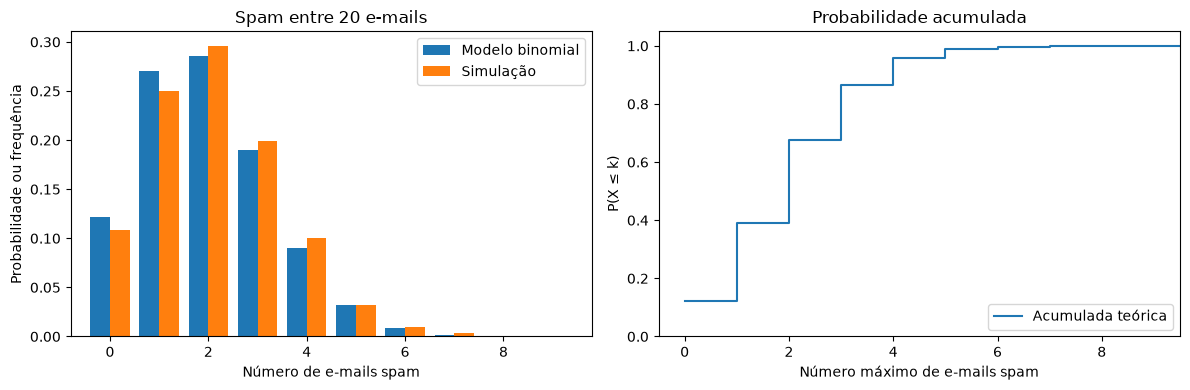

In [55]:
# COMPARE MASSAS TEÓRICAS, FREQUÊNCIAS E ACUMULADA.
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].bar(np.array(valores_x) - 0.2, prob_x, width=0.4, label="Modelo binomial")
eixos[0].bar(np.array(valores_x) + 0.2, freq_x, width=0.4, label="Simulação")
eixos[0].set(xlabel="Número de e-mails spam", ylabel="Probabilidade ou frequência", title="Spam entre 20 e-mails", xlim=(-0.8, 9.8))
eixos[0].legend()
eixos[1].step(valores_x, np.cumsum(prob_x), where="post", label="Acumulada teórica")
eixos[1].set(xlabel="Número máximo de e-mails spam", ylabel="P(X ≤ k)", title="Probabilidade acumulada", xlim=(-0.5, 9.5), ylim=(0, 1.05))
eixos[1].legend(loc="lower right")
fig.tight_layout()
plt.show()

**Figura 1 - Massa Binomial, simulação e acumulada.** À esquerda, dois e-mails spam estão entre as contagens mais prováveis no modelo de 20 e-mails com $p=0{,}10$, e as frequências simuladas ficam próximas das massas teóricas. À direita, cada degrau acumula as massas até o número de e-mails spam indicado. Visualização inspirada no Seeing Theory (SEEING THEORY, s. d.).

**Variação guiada.** Altere $p$ para $0{,}20$ e compare a esperança, a variância e o deslocamento das barras. O número de ensaios continua fixo.

### 5.7 Síntese da Aula 5

A variável $X$ conta as ocorrências do evento “o e-mail é spam” entre 20 e-mails. O modelo Binomial exige número fixo de ensaios, independência entre as variáveis $X_i$ e probabilidade $p$ constante. A forma do gráfico não estabelece essas condições. Antes de calcular, registre o evento de interesse, $n$, $p$ e os valores possíveis de $X$.

## 6. Distribuição de Poisson

Agora, o evento de interesse é a chegada de uma requisição ao servidor. Fixamos uma **janela de tempo** e contamos quantas vezes esse evento ocorre. O número de chegadas não foi fixado antes da observação.

### 6.1 Mecanismo, variável e parâmetro

Seja $\Omega$ o conjunto dos possíveis registros de chegadas durante a janela. A variável $Y_t:\Omega\longrightarrow\{0,1,2,\ldots\}$ associa a cada registro o número de requisições recebidas nos $t$ minutos. Um processo de Poisson homogêneo pressupõe independência entre intervalos disjuntos, taxa estável e chance desprezível de duas ocorrências em um intervalo muito curto (BARBETTA; REIS; BORNIA, 2010, pp. 133–134; MONTGOMERY; RUNGER, 2018, p. 63).

Se $r$ é a taxa média de chegadas por minuto, a média esperada na janela é

$$
\lambda=rt,\qquad Y_t\sim\operatorname{Poisson}(\lambda),\qquad \lambda>0.\tag{6.1}
$$

A taxa $r$ tem unidade chegadas/minuto. O intervalo $t$ tem unidade minuto. O parâmetro $\lambda$ é o número médio esperado de chegadas **nessa janela**. Para $r=5$, temos $\lambda=5$ em um minuto e $\lambda=2{,}5$ em 30 segundos. A constância de uma média observada não comprova as demais hipóteses (BARBETTA; REIS; BORNIA, 2010, pp. 134–135; MONTGOMERY; RUNGER, 2018, pp. 63–64).

In [56]:
# CONVERTA A TAXA PARA AS DUAS JANELAS DE OBSERVAÇÃO.
taxa = 5.0  # chegadas por minuto
lambda_1min = taxa * 1.0
lambda_30s = taxa * 0.5
print("Média em um minuto:", lambda_1min, "chegadas")
print("Média em 30 segundos:", lambda_30s, "chegadas")

Média em um minuto: 5.0 chegadas
Média em 30 segundos: 2.5 chegadas


Ao reduzir a janela pela metade, a média esperada passa de 5 para 2,5 chegadas. Empregar $\lambda=5$ para 30 segundos representaria outra taxa.

### 6.2 Função de probabilidade e acumulada

Para uma janela fixa de $t$ minutos, escreva $Y=Y_t$ e $\lambda=rt$. Se $Y\sim\operatorname{Poisson}(\lambda)$, a probabilidade de exatamente $k$ chegadas é

$$
f_Y(k)=\mathbb P(Y=k)=e^{-\lambda}\frac{\lambda^k}{k!},\qquad k\in\{0,1,2,\ldots\}.\tag{6.2}
$$

O valor $k=0$ está incluído: $f_Y(0)=e^{-\lambda}$ (BARBETTA; REIS; BORNIA, 2010, p. 135; MONTGOMERY; RUNGER, 2018, p. 63). Aqui $e$ é a base da função exponencial, $\lambda$ é a média na janela e $k!$ é o fatorial de $k$. A função acumulada fornece a probabilidade de ocorrerem no máximo $k$ chegadas:

$$
F_Y(k)=\mathbb P(Y\leq k)=\sum_{j=0}^{k}f_Y(j),\qquad
\mathbb P(Y>k)=1-F_Y(k).\tag{6.3}
$$

O índice $j$ percorre as contagens incluídas. O complemento representa mais de $k$ chegadas, não pelo menos $k$ (BARBETTA; REIS; BORNIA, 2010, p. 135; MONTGOMERY; RUNGER, 2018, seção 3.2, pp. 45–46).

### 6.3 Esperança e variância

No modelo de Poisson, as duas propriedades têm o mesmo valor numérico (BARBETTA; REIS; BORNIA, 2010, p. 135; MONTGOMERY; RUNGER, 2018, p. 65):

$$
\mathbb E[Y]=\lambda.\tag{6.4}
$$

$$
\operatorname{Var}(Y)=\lambda.\tag{6.5}
$$

A esperança usa a unidade da contagem e a variância usa essa unidade ao quadrado. Para $\lambda=5$, são 5 chegadas e 5 chegadas^2, respectivamente. Em dados observados, variância muito maior que a média sugere inadequação do modelo. Valores próximos não provam ajuste (MONTGOMERY; RUNGER, 2018, p. 65).

### 6.4 Implementação Manual

Fixe $t=1$ minuto, de modo que $Y=Y_1$ e $\lambda=5$. Calcule as probabilidades de $Y=k$ com `math.exp` e `math.factorial`, da biblioteca padrão. Como Poisson permite contagens arbitrariamente altas, uma soma interrompida em um valor deixa uma cauda fora da tabela.

In [ ]:
# Calcular a probabilidade de Poisson pela definição
from math import exp, factorial


def prob_poisson(k: int, lam: float) -> float:
    """Calcula a probabilidade de exatamente k ocorrências com média lam."""
    if k < 0:
        raise ValueError('Use uma contagem k não negativa.')
    if lam <= 0:
        raise ValueError('Use uma média lam positiva.')
    return exp(-lam) * lam**k / factorial(k)

In [ ]:
# CALCULE MASSAS E ACUMULADA EM UM MINUTO.
valores_y = list(range(13))
prob_y = [prob_poisson(k, lambda_1min) for k in valores_y]
print("P(Y = 0):", round(prob_y[0], 6))
print("P(Y = 2):", round(prob_y[2], 6))
print("P(Y ≤ 2):", round(sum(prob_y[:3]), 6))
print("P(Y > 12):", round(1 - sum(prob_y), 6))

P(Y = 0): 0.006738
P(Y = 2): 0.084224
P(Y ≤ 2): 0.124652
P(Y > 12): 0.002019


A probabilidade acima de 12 chegadas é pequena, mas positiva. A soma truncada até 12 não é a massa total do modelo.

### 6.5 Conferência com Biblioteca, simulação e gráfico

Compare os cálculos com `scipy.stats.poisson`. Uma nova amostra de 1.000 minutos ilustra a variabilidade da simulação. A massa além do último valor visível continua pertencendo ao modelo (SCIPY COMMUNITY, s. d.).

In [58]:
# CONFIRA A FUNÇÃO MASSA, A ACUMULADA E OS MOMENTOS.
from scipy.stats import poisson

print("P(Y = 2):", round(poisson.pmf(2, lambda_1min), 6))
print("P(Y ≤ 2):", round(poisson.cdf(2, lambda_1min), 6))
print("Esperança:", poisson.mean(lambda_1min), "chegadas")
print("Variância:", poisson.var(lambda_1min), "chegadas^2")

P(Y = 2): 0.084224
P(Y ≤ 2): 0.124652
Esperança: 5.0 chegadas
Variância: 5.0 chegadas^2


In [59]:
# SIMULE MIL MINUTOS COM SEMENTE FIXA.
amostra_y = poisson.rvs(lambda_1min, size=1000, random_state=np.random.default_rng(2027))
freq_y = [sum(amostra_y == k) / len(amostra_y) for k in valores_y]
print("Média simulada:", round(float(np.mean(amostra_y)), 4), "chegadas")
print("Variância simulada:", round(float(np.var(amostra_y)), 4), "chegadas^2")
print("Massa acima de 12:", round(poisson.sf(12, lambda_1min), 6))

Média simulada: 5.111 chegadas
Variância simulada: 4.8467 chegadas^2
Massa acima de 12: 0.002019


A média e a variância da amostra são valores observados em 1.000 minutos simulados. Podem diferir dos valores teóricos $\lambda=5$. A probabilidade acima de 12 chegadas explica por que o gráfico não mostra toda a massa.

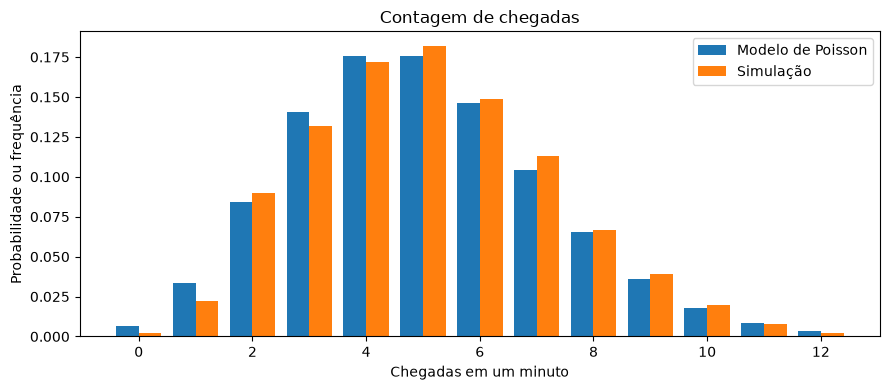

In [60]:
# COMPARE A SIMULAÇÃO COM AS MASSAS TEÓRICAS VISÍVEIS.
fig, eixo = plt.subplots(figsize=(9, 4))
eixo.bar(np.array(valores_y) - 0.2, prob_y, width=0.4, label="Modelo de Poisson")
eixo.bar(np.array(valores_y) + 0.2, freq_y, width=0.4, label="Simulação")
eixo.set(xlabel="Chegadas em um minuto", ylabel="Probabilidade ou frequência", title="Contagem de chegadas")
eixo.legend()
fig.tight_layout()
plt.show()

**Figura 2 - Chegadas em um minuto.** Sob $\operatorname{Poisson}(5)$, quatro e cinco chegadas têm as maiores massas, e as frequências simuladas ficam próximas. O gráfico mostra até 12 chegadas. Há uma pequena cauda acima desse valor. Visualização inspirada no Seeing Theory (SEEING THEORY, s. d.).

## 7. Aproximação Binomial–Poisson

Nesta seção, $X$ é o número de sucessos em $n$ ensaios independentes, cada um com probabilidade $p$ de sucesso. $Y$ é uma contagem de Poisson usada para aproximar $X$. Quando $n$ é grande e $p$ pequeno, estabeleça $\lambda=np$ e compare as probabilidades do mesmo evento nas duas distribuições (BARBETTA; REIS; BORNIA, 2010, p. 136, exemplo 5.5; MONTGOMERY; RUNGER, 2018, p. 63).

$$
X\sim\operatorname{Binomial}(n,p),\quad Y\sim\operatorname{Poisson}(np),\quad
\mathbb P(X>k)\approx\mathbb P(Y>k).\tag{6.6}
$$

No exemplo, $n=500$, $p=0{,}005$ e $\lambda=2{,}5$. O evento comparado é $\{X>4\}$ na Binomial e $\{Y>4\}$ na aproximação de Poisson. Não existe um limiar universal de $n$ e $p$ que garanta a mesma precisão em todos os eventos. A Binomial exata permite avaliar o erro neste caso.

In [ ]:
# CALCULE A CAUDA BINOMIAL EXATA E A APROXIMAÇÃO PELAS FÓRMULAS.
n_aprox = 500
p_aprox = 0.005
lambda_aprox = n_aprox * p_aprox
bin_ate4 = sum(prob_binom(k, n_aprox, p_aprox) for k in range(5))
poi_ate4 = sum(prob_poisson(k, lambda_aprox) for k in range(5))
exata = 1 - bin_ate4
aproximada = 1 - poi_ate4
print("Binomial exata P(X > 4):", round(exata, 6))
print("Poisson aproximada P(Y > 4):", round(aproximada, 6))
print("Diferença absoluta:", round(abs(exata - aproximada), 6))

Binomial exata P(X > 4): 0.108319
Poisson aproximada P(Y > 4): 0.108822
Diferença absoluta: 0.000503


A diferença absoluta quantifica o erro **neste evento** e para **estes parâmetros**. Ela não determina a qualidade da aproximação em outras situações.

In [62]:
# CONFIRA AS DUAS CAUDAS COM A BIBLIOTECA.
print("Binomial, SciPy:", round(binom.sf(4, n_aprox, p_aprox), 6))
print("Poisson, SciPy:", round(poisson.sf(4, lambda_aprox), 6))

Binomial, SciPy: 0.108319
Poisson, SciPy: 0.108822


As caudas conferidas coincidem com as calculadas pelas fórmulas. Nesta seção, Poisson aproxima uma Binomial. Na contagem de chegadas, ela foi proposta diretamente para ocorrências no tempo.

## 8. Comparação dos mecanismos e fechamento

**Binomial:** $X$ conta em quantos dos $n$ e-mails ocorreu o evento “o e-mail é spam”. Verifique independência e $p$ constante. **Poisson:** $Y_t$ conta quantas chegadas ocorreram na janela de $t$ minutos. Verifique as condições do processo e use $\lambda=rt$. Na aproximação Binomial–Poisson, compare a mesma condição sobre a contagem nos dois modelos e use a Binomial exata para avaliar o erro.

## 9. Estudo e exercícios

### 9.1 Materiais didáticos

- BARBETTA; REIS; BORNIA (2010), seção 5.2: Bernoulli, Binomial, Poisson e aproximação Binomial–Poisson.
- MONTGOMERY; RUNGER (2018), seções 3.1, 3.2, 3.5 e 3.8: função de probabilidade, acumulada e mecanismos Binomial e de Poisson.
- DEVLIN et al. (2018), *Basic probability*, pp. 10–13, e *Probability distributions*, pp. 31–35: esperança, variância e massas.
- [Seeing Theory: Probability distributions](https://seeing-theory.brown.edu/probability-distributions/index.html): exploração visual dos parâmetros.

### 9.2 Exercícios indicados

- **Binomial:** BARBETTA; REIS; BORNIA (2010), capítulo 5, exercício 5.7, p. 131 da edição impressa. Calcule as probabilidades e esperanças solicitadas para lotes de 20 itens com $p=0{,}05$ de defeito por item.
- **Poisson:** BARBETTA; REIS; BORNIA (2010), capítulo 5, exercício 5.11, p. 136 da edição impressa. Calcule as probabilidades solicitadas para uma taxa de cinco chegadas por minuto e para janelas de um minuto e 30 segundos.

Os CSVs usados a seguir são **simulações didáticas** com semente fixa. Suas frequências não substituem as probabilidades teóricas dos exercícios. O carregamento pela nuvem permite executar o notebook no Colab.

### 9.3 Aplicação Binomial com dados sintéticos

O arquivo de [lotes simulados](https://raw.githubusercontent.com/carubbi/MQ/8936fddacaf80892e611f4fb9fc9daec8601b7af/notebooks/assets/data/u2_s03_binomial_ex07.csv) tem uma linha por lote, com o número de itens defeituosos e bons. Primeiro resolva o exercício 5.7 pelo modelo. Depois confronte as respostas com a simulação.

In [63]:
# CARREGUE OS LOTES SINTÉTICOS PELA NUVEM.
import pandas as pd

base = "https://raw.githubusercontent.com/carubbi/MQ/8936fddacaf80892e611f4fb9fc9daec8601b7af/notebooks/assets/data/"
df_bin = pd.read_csv(base + "u2_s03_binomial_ex07.csv")
print("Lotes:", len(df_bin))
display(df_bin.head(3))

Lotes: 5000


,lote,defeituosos,bons
0,1,1,19
1,2,0,20
2,3,0,20


**Tabela 1 - Lotes sintéticos.** Cada linha representa um lote de 20 itens. As colunas registram quantos itens são defeituosos e quantos são bons. Suas contagens somam 20 em cada lote.

**Aplicação do exercício 5.7.** Defina $D$ como o número de itens defeituosos em um lote. Sob as condições Binomiais do enunciado, use $D\sim\operatorname{Binomial}(20,0{,}05)$ (BARBETTA; REIS; BORNIA, 2010, p. 131, exercício 5.7). Calcule $\mathbb P(D\geq1)$, $\mathbb P(D=2)$ e $\mathbb P(D>2)$, além dos números esperados de itens defeituosos e bons. Compare com o CSV.

In [64]:
# RESOLVA AS PROBABILIDADES E MÉDIAS TEÓRICAS DO EXERCÍCIO 5.7.
n_ex = 20
p_ex = 0.05
print("Teórica P(D ≥ 1):", round(1 - binom.pmf(0, n_ex, p_ex), 4))
print("Teórica P(D = 2):", round(binom.pmf(2, n_ex, p_ex), 4))
print("Teórica P(D > 2):", round(binom.sf(2, n_ex, p_ex), 4))
print("E[D]:", n_ex * p_ex, "defeituoso por lote")
print("E[bons]:", n_ex * (1 - p_ex), "bons por lote")

# COMPARE COM OS LOTES SINTÉTICOS.
print("Frequência D ≥ 1:", round((df_bin["defeituosos"] >= 1).mean(), 4))
print("Frequência D = 2:", round((df_bin["defeituosos"] == 2).mean(), 4))
print("Frequência D > 2:", round((df_bin["defeituosos"] > 2).mean(), 4))
print("Médias simuladas:", round(df_bin["defeituosos"].mean(), 4), "e", round(df_bin["bons"].mean(), 4))

Teórica P(D ≥ 1): 0.6415
Teórica P(D = 2): 0.1887
Teórica P(D > 2): 0.0755
E[D]: 1.0 defeituoso por lote
E[bons]: 19.0 bons por lote
Frequência D ≥ 1: 0.6436
Frequência D = 2: 0.1914
Frequência D > 2: 0.0722
Médias simuladas: 0.9998 e 19.0002


As probabilidades são propriedades de $\operatorname{Binomial}(20,0{,}05)$. As frequências vêm de 5.000 lotes simulados e podem diferir das probabilidades mesmo quando o mecanismo gerador é o mesmo.

### 9.4 Aplicação de Poisson com dados sintéticos

O arquivo de [chegadas simuladas](https://raw.githubusercontent.com/carubbi/MQ/8936fddacaf80892e611f4fb9fc9daec8601b7af/notebooks/assets/data/u2_s03_poisson_ex11.csv) tem uma linha por minuto. As duas metades de 30 segundos e o total do minuto permitem conferir a mudança de janela do exercício 5.11.

In [65]:
# CARREGUE AS CONTAGENS DE CHEGADAS PELA NUVEM.
df_poi = pd.read_csv(base + "u2_s03_poisson_ex11.csv")
print("Minutos:", len(df_poi))
display(df_poi.head(3))

Minutos: 5000


,minuto,chegadas_0_30s,chegadas_30_60s,chegadas_1min
0,1,2,4,6
1,2,6,3,9
2,3,2,1,3


**Tabela 2 - Chegadas sintéticas.** Cada linha representa um minuto. A soma das chegadas nas duas metades de 30 segundos fornece a contagem total do minuto.

**Aplicação do exercício 5.11.** Seja $C_t$ o número de chegadas em $t$ minutos, com taxa de cinco por minuto. Calcule $\mathbb P(C_1=2)$ para um minuto e $\mathbb P(C_{0,5}=1)$ para 30 segundos. Use $\lambda=5$ e $\lambda=2{,}5$ nas respectivas janelas e compare com o CSV (BARBETTA; REIS; BORNIA, 2010, p. 136, exercício 5.11).

In [66]:
# RESOLVA AS PROBABILIDADES TEÓRICAS DO EXERCÍCIO 5.11.
print("Teórica P(2 em um minuto):", round(poisson.pmf(2, 5), 4))
print("Teórica P(1 em 30 segundos):", round(poisson.pmf(1, 2.5), 4))

# COMPARE COM AS CONTAGENS SINTÉTICAS.
print("Frequência de 2 em um minuto:", round((df_poi["chegadas_1min"] == 2).mean(), 4))
print("Frequência de 1 nos primeiros 30 segundos:", round((df_poi["chegadas_0_30s"] == 1).mean(), 4))
print("Média simulada por minuto:", round(df_poi["chegadas_1min"].mean(), 4))

Teórica P(2 em um minuto): 0.0842
Teórica P(1 em 30 segundos): 0.2052
Frequência de 2 em um minuto: 0.0852
Frequência de 1 nos primeiros 30 segundos: 0.2134
Média simulada por minuto: 5.0098


A simulação usa a primeira metade de cada minuto para comparar janelas de 30 segundos. A frequência de uma chegada nessa metade não precisa coincidir exatamente com $\mathbb P(C_{0,5}=1)$.

## 10. Referências

1. BARBETTA, Pedro Alberto; REIS, Marcelo Menezes; BORNIA, Antonio Cezar. *Estatística para cursos de engenharia e informática*. 3. ed. São Paulo: Atlas, 2010. Seção 5.2.
2. MONTGOMERY, Douglas C.; RUNGER, George C. *Applied Statistics and Probability for Engineers*. 7. ed. Hoboken: Wiley, 2018. Seções 3.1, 3.2, 3.5 e 3.8.
3. DEVLIN, Tyler Dae; GUO, Jingru; KUNIN, Daniel; XIANG, Daniel. **Basic probability**. In: *Seeing Theory: a visual introduction to probability and statistics*. [S. l.]: Seeing Theory, 2018. p. 5–18. Disponível em: https://seeing-theory.brown.edu/doc/seeing-theory.pdf. Acesso em: 9 out. 2026.
4. DEVLIN, Tyler Dae; GUO, Jingru; KUNIN, Daniel; XIANG, Daniel. **Probability distributions**. In: *Seeing Theory: a visual introduction to probability and statistics*. [S. l.]: Seeing Theory, 2018. p. 31–40. Disponível em: https://seeing-theory.brown.edu/doc/probability-distributions.pdf. Acesso em: 8 out. 2026.
5. SCIPY COMMUNITY. **Statistical functions (scipy.stats)**. [S. l.], [s. d.]. Disponível em: https://docs.scipy.org/doc/scipy/reference/stats.html. Acesso em: 8 out. 2026.
6. SEEING THEORY. **Probability distributions**. [S. l.], [s. d.]. Disponível em: https://seeing-theory.brown.edu/probability-distributions/index.html. Acesso em: 8 out. 2026.